In [1]:
import pandas as pd

In [3]:
df = pd.read_excel("House_Price_Prediction_100_Records.xlsx")
df

,Area_sqft,Bedrooms,House_Age_Years,Location_Score,Price
0,1660,2,0,6,40000
1,2094,2,7,6,32000
2,1930,4,6,5,35000
3,1895,5,17,8,48000
4,2438,3,7,9,53000
...,...,...,...,...,...
95,1197,3,5,6,29000
96,1670,3,5,4,33000
97,1192,4,12,5,27000
98,1006,4,18,10,37000


In [4]:
x = df[['Area_sqft','Bedrooms','House_Age_Years','Location_Score']]
y = df['Price']

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 11.33, 857.11,-169.67,2602.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Area_sqft','Bedrooms','House_Age_Years','Location_Score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-337.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [7]:
y_pred = model.predict(X_test)

In [17]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
r2 = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))

print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))

print(model.intercept_)
for col, coef in zip(x.columns, model.coef_):
    print(col,coef)



0.7223229528987827
4363.984915501783
28181443.510302536
-337.41774730304314
Area_sqft 11.331056674289787
Bedrooms 857.1088361699315
House_Age_Years -169.67463580171807
Location_Score 2602.21992152795


In [19]:
new = pd.DataFrame(
    [
        {
            'Area_sqft':2000,
            'Bedrooms':3,
            'House_Age_Years':5,
            'Location_Score':8
        }
    ]
)
prediction_price = model.predict(new)[0]
print(prediction_price)

44865.408303001335


Text(0.5, 1.0, 'Actual vs Predicted House Prices')

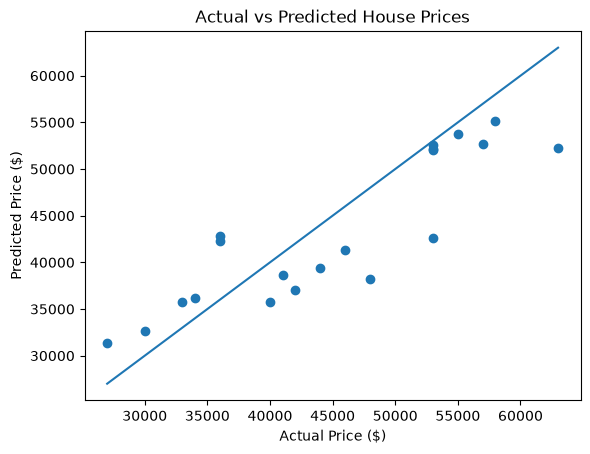

In [20]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted House Prices')